In [1]:
from pathlib import Path
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

%matplotlib inline
available_fonts = {item.name for item in font_manager.fontManager.ttflist}
for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic",
                  "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams.update({"figure.figsize": (8, 4.6), "font.size": 12,
                     "axes.unicode_minus": False, "axes.spines.top": False,
                     "axes.spines.right": False})
print("준비 완료. 이후 셀은 위에서 아래 순서로 실행합니다.")


준비 완료. 이후 셀은 위에서 아래 순서로 실행합니다.


In [6]:
csv_text = 'pot_id,place,sunlight_hours,water_ml,height_cm\nP01,실내,2,0,8\nP02,실내,3,20,10\nP03,창가,5,,12\nP04,창가,6,40,14\nP05,실내,4,20,10\nP06,창가,7,60,18\n'
csv_path = Path("data/week1_plants.csv")
if csv_path.is_file():
    plants = pd.read_csv(csv_path)
    print("읽은 자료:", csv_path)
else:
    plants = pd.read_csv(StringIO(csv_text))
    print("읽은 자료: 노트북에 포함된 동일한 CSV")
display(plants)


읽은 자료: data/week1_plants.csv


,pot_id,place,sunlight_hours,water_ml,height_cm
0,P01,실내,2,0.0,8
1,P02,실내,3,20.0,10
2,P03,창가,5,NaN,12
3,P04,창가,6,40.0,14
4,P05,실내,4,20.0,10
5,P06,창가,7,60.0,18


In [17]:
new_csv_text = 'sample_id,site,light_hours,water_amount_ml,final_height_cm\nQ01,실내,1,0,7\nQ02,실내,2,,9\nQ03,창가,4,20,12\nQ04,창가,5,40,14\n'
new_path = Path("data/week1_plants_new.csv")
new_plants = (pd.read_csv(new_path) if new_path.is_file()
              else pd.read_csv(StringIO(new_csv_text)))
B = np.array([[1, 5, 9], [3, 7, 11]], dtype=float)
display(new_plants)


,sample_id,site,light_hours,water_amount_ml,final_height_cm
0,Q01,실내,1,0.0,7
1,Q02,실내,2,NaN,9
2,Q03,창가,4,20.0,12
3,Q04,창가,5,40.0,14


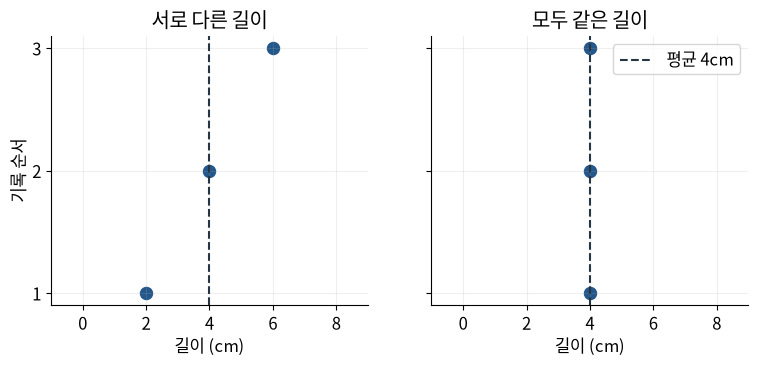

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharex=True, sharey=True)
groups = [("서로 다른 길이", [2, 4, 6]), ("모두 같은 길이", [4, 4, 4])]
for ax, (name, group) in zip(axes, groups):
    ax.scatter(group, [1, 2, 3], s=75, color="#24578A")
    ax.axvline(np.mean(group), color="#263544", linestyle="--", label="평균 4cm")
    ax.set(title=name, xlabel="길이 (cm)", xlim=(-1, 9), yticks=[1, 2, 3])
    ax.grid(alpha=0.2)
axes[0].set_ylabel("기록 순서")
axes[1].legend()
plt.show()


,평균 높이(cm),기록 수
place,,
실내,9.333333,3
창가,14.666667,3


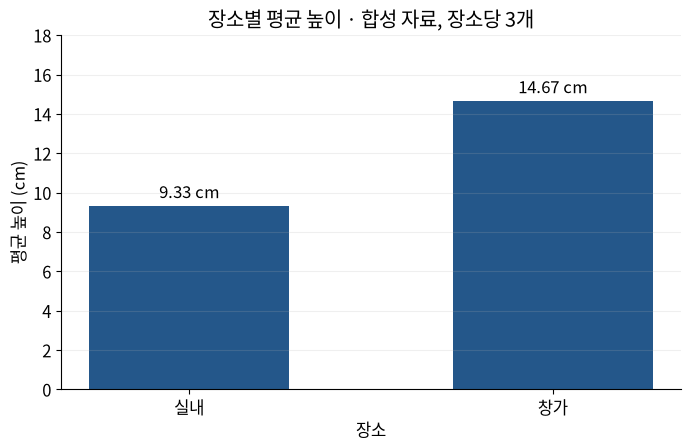

In [23]:
place_summary = plants.groupby("place", sort=True)["height_cm"].agg(["mean", "count"])
display(place_summary.rename(columns={"mean": "평균 높이(cm)", "count": "기록 수"}))
fig, ax = plt.subplots()
bars = ax.bar(place_summary.index, place_summary["mean"],
              color="#24578A", width=0.55)
ax.bar_label(bars, fmt="%.2f cm", padding=4)
ax.set(title="장소별 평균 높이 · 합성 자료, 장소당 3개",
       xlabel="장소", ylabel="평균 높이 (cm)", ylim=(0, 18))
ax.grid(axis="y", alpha=0.2)
plt.show()


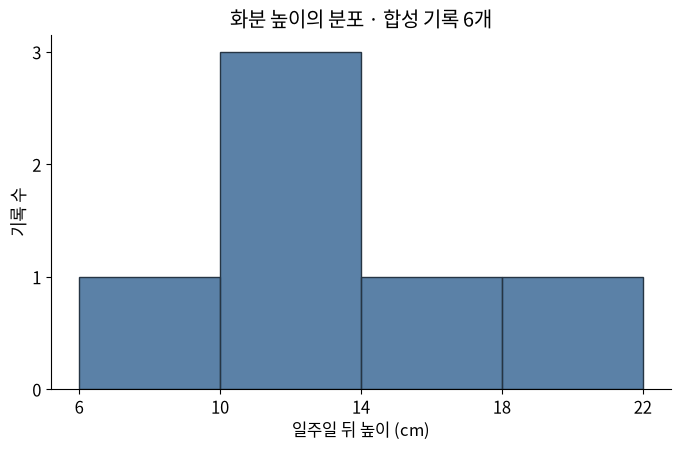

In [24]:
import seaborn as sns

fig, ax = plt.subplots()
sns.histplot(data=plants, x="height_cm", bins=[6, 10, 14, 18, 22],
             color="#24578A", edgecolor="#263544", ax=ax)
ax.set(title="화분 높이의 분포 · 합성 기록 6개",
       xlabel="일주일 뒤 높이 (cm)", ylabel="기록 수",
       xticks=[6, 10, 14, 18, 22], yticks=[0, 1, 2, 3])
plt.show()


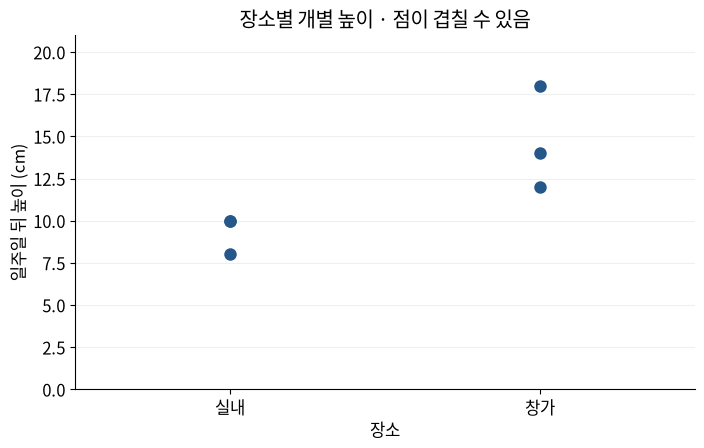

In [25]:
fig, ax = plt.subplots()
sns.stripplot(data=plants, x="place", y="height_cm", order=["실내", "창가"],
              jitter=False, color="#24578A", size=9, ax=ax)
ax.set(title="장소별 개별 높이 · 점이 겹칠 수 있음",
       xlabel="장소", ylabel="일주일 뒤 높이 (cm)", ylim=(0, 21))
ax.grid(axis="y", alpha=0.2)
plt.show()
